## Step 1: Dataset Preparation:

This step involves parsing the images and masks by applying the necessary transformation (such as resize). We do so by defining a custom dataset class and writing the methods for getting the images, applying the transformation and returning them. This step also involves the preparation of train, test and validations set, which are required for the training, validation and evaluation of the model respectively.


In [11]:
import torch
import torchvision.transforms as transform
from torchvision.transforms import CenterCrop
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import tqdm as tqdm
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os
import glob

import torchvision.transforms.functional as TF


import pandas as pd
import random

from torch.utils.data import Dataset, DataLoader
import torchvision.models as models

import albumentations as A
from albumentations.pytorch import  ToTensorV2

from sklearn.model_selection import train_test_split

In [12]:
DATA_PATH = "/kaggle/input/mri-data/lgg-mri-segmentation/kaggle_3m/"


# File path line length images for later sorting
BASE_LEN = 67 # len("../data/mri_data/TCGA_DU_6404_19850629/TCGA_DU_6404_19850629_10.tif")
END_IMG_LEN = 4 # llen("../data/mri_data/TCGA_DU_6404_19850629/TCGA_DU_6404_19850629_10.tif")
END_MASK_LEN = 9 # (/kaggle/input/lgg-mri-segmentation/kaggle_3m/TCGA_DU_6404_19850629/TCGA_DU_6404_19850629_43 !!!->_mask.tif)

# img size
IMG_SIZE = 512

In [13]:
data_map = []
for sub_dir_path in glob.glob(DATA_PATH+"*"):
    if os.path.isdir(sub_dir_path):
        dirname = sub_dir_path.split("/")[-1]
        for filename in os.listdir(sub_dir_path):
            image_path = sub_dir_path + "/" + filename
            data_map.extend([dirname, image_path])

    else:
        print("Not a dir: ", sub_dir_path)

df = pd.DataFrame({"dirname" : data_map[::2], "path": data_map[1::2]})
df.head()

Not a dir:  /kaggle/input/mri-data/lgg-mri-segmentation/kaggle_3m/README.md
Not a dir:  /kaggle/input/mri-data/lgg-mri-segmentation/kaggle_3m/data.csv


,dirname,path
0,TCGA_DU_7010_19860307,/kaggle/input/mri-data/lgg-mri-segmentation/ka...
1,TCGA_DU_7010_19860307,/kaggle/input/mri-data/lgg-mri-segmentation/ka...
2,TCGA_DU_7010_19860307,/kaggle/input/mri-data/lgg-mri-segmentation/ka...
3,TCGA_DU_7010_19860307,/kaggle/input/mri-data/lgg-mri-segmentation/ka...
4,TCGA_DU_7010_19860307,/kaggle/input/mri-data/lgg-mri-segmentation/ka...


In [14]:
# Separate the mask and image
df_imgs = df[~df["path"].str.contains("mask")]
df_masks = df[df["path"].str.contains("mask")]

# Function to extract number from filename for proper sorting
def extract_number_from_path(path):
    """extract the numeric identifier from the file path for sorting."""
    try:
        filename = os.path.basename(path)
        filename_no_ext = os.path.splitext(filename)[0]

        if '_mask' in filename_no_ext:
            filename_no_ext = filename_no_ext.replace('_mask', '')

        parts = filename_no_ext.split('_')
        number_str = parts[-1]

        return int(number_str)
    except (ValueError, IndexError) as e:
        print(f"Error processing path {path}: {e}")
        return 0

# sort images and masks using the improved extraction function
imgs = sorted(df_imgs["path"].values, key=extract_number_from_path)
masks = sorted(df_masks["path"].values, key=extract_number_from_path)


In [15]:
print("\nFirst 5 image paths:")
for i in range(min(5, len(imgs))):
    print(f"  {imgs[i]}")

print("\nFirst 5 mask paths:")
for i in range(min(5, len(masks))):
    print(f"  {masks[i]}")

# Check correspondence between images and masks
idx = random.randint(0, min(len(imgs), len(masks)) - 1)
print(f"\nRandom sample check (index {idx}):")
print("Path to the Image: ", imgs[idx])
print("Path to the Mask: ", masks[idx])

# Verify we have matching pairs
if len(imgs) == len(masks):
    print(f"\nPerfect match: {len(imgs)} image-mask pairs")
else:
    print(f"\nMismatch: {len(imgs)} images vs {len(masks)} masks")


First 5 image paths:
  /kaggle/input/mri-data/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_1.tif
  /kaggle/input/mri-data/lgg-mri-segmentation/kaggle_3m/TCGA_DU_8162_19961029/TCGA_DU_8162_19961029_1.tif
  /kaggle/input/mri-data/lgg-mri-segmentation/kaggle_3m/TCGA_FG_A4MT_20020212/TCGA_FG_A4MT_20020212_1.tif
  /kaggle/input/mri-data/lgg-mri-segmentation/kaggle_3m/TCGA_FG_5964_20010511/TCGA_FG_5964_20010511_1.tif
  /kaggle/input/mri-data/lgg-mri-segmentation/kaggle_3m/TCGA_DU_A5TS_19970726/TCGA_DU_A5TS_19970726_1.tif

First 5 mask paths:
  /kaggle/input/mri-data/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_1_mask.tif
  /kaggle/input/mri-data/lgg-mri-segmentation/kaggle_3m/TCGA_DU_8162_19961029/TCGA_DU_8162_19961029_1_mask.tif
  /kaggle/input/mri-data/lgg-mri-segmentation/kaggle_3m/TCGA_FG_A4MT_20020212/TCGA_FG_A4MT_20020212_1_mask.tif
  /kaggle/input/mri-data/lgg-mri-segmentation/kaggle_3m/TCGA_FG_5964_20010511/TCGA_FG_5964_200

The test dataset consists of only images (not masks), so lets create a separate class to parse and return the image.

In [16]:
from PIL import Image as PilImage

In [17]:
class TestDataset(Dataset):
    def __init__(self, images_dir, transform=None):
        self.images_dir = images_dir
        self.image_filenames = sorted(os.listdir(images_dir))
        self.transform = transform

    def __len__(self):
        return len(self.image_filenames)

    def __getitem__(self, idx):
        img_path = os.path.join(self.images_dir, self.image_filenames[idx])
        image = PilImage.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image

In [18]:
df = pd.DataFrame({"patient": df_imgs.dirname.values, "image_path": imgs, "mask_path": masks})

def diagnosis(mask_path):
    value = np.max(cv2.imread(mask_path))
    if value > 0 : return 1
    else: return 0


df["diagnosis"] = df["mask_path"].apply(lambda m: diagnosis(m))
df.head()


# from joblib import Parallel, delayed
# import cv2
# import numpy as np
# # Make sure imgs and masks are sorted properly first
# imgs = sorted(df_imgs["path"].values, key=extract_number_from_path)
# masks = sorted(df_masks["path"].values, key=extract_number_from_path)

# # Rebuild DataFrame with matching image and mask pairs
# df = pd.DataFrame({
#     "image_path": imgs,
#     "mask_path": masks,
#     "patient": [os.path.basename(p).split('_')[0] for p in imgs]  # Optional: patient ID
# })
# def diagnosis(mask_path):
#     value = np.max(cv2.imread(mask_path, cv2.IMREAD_UNCHANGED))
#     return 1 if value > 0 else 0

# from tqdm import tqdm  # for a nice progress bar

# results = Parallel(n_jobs=-1)(
#     delayed(diagnosis)(path) for path in tqdm(df["mask_path"])
# )

# df["diagnosis"] = results


,patient,image_path,mask_path,diagnosis
0,TCGA_DU_7010_19860307,/kaggle/input/mri-data/lgg-mri-segmentation/ka...,/kaggle/input/mri-data/lgg-mri-segmentation/ka...,0
1,TCGA_DU_7010_19860307,/kaggle/input/mri-data/lgg-mri-segmentation/ka...,/kaggle/input/mri-data/lgg-mri-segmentation/ka...,0
2,TCGA_DU_7010_19860307,/kaggle/input/mri-data/lgg-mri-segmentation/ka...,/kaggle/input/mri-data/lgg-mri-segmentation/ka...,0
3,TCGA_DU_7010_19860307,/kaggle/input/mri-data/lgg-mri-segmentation/ka...,/kaggle/input/mri-data/lgg-mri-segmentation/ka...,0
4,TCGA_DU_7010_19860307,/kaggle/input/mri-data/lgg-mri-segmentation/ka...,/kaggle/input/mri-data/lgg-mri-segmentation/ka...,0


In [19]:
total_ones = (df["diagnosis"] == 1).sum()
print("Total number of 1s in diagnosis:", total_ones)

Total number of 1s in diagnosis: 1373


In [20]:
!mkdir /kaggle/working/outputs

=== Dataset Distribution Analysis ===
Total samples: 3929
Positive samples (with tumor): 1373
Negative samples (no tumor): 2556
Percentage of positive samples: 34.95%
Percentage of negative samples: 65.05%

Total number of unique patients: 110
Average images per patient: 35.72
Min images per patient: 20
Max images per patient: 88


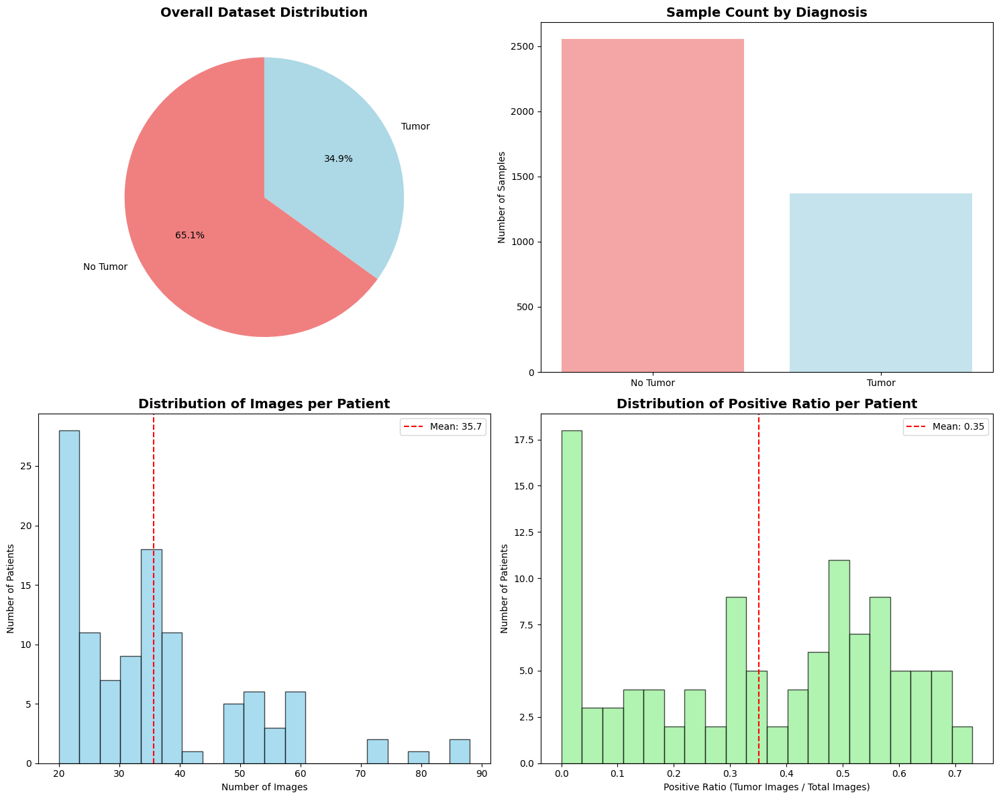


=== Patient-wise Summary Statistics ===
Patients with only negative samples: 18
Patients with only positive samples: 0
Patients with mixed samples: 92


In [21]:
# Dataset Distribution Analysis
print("=== Dataset Distribution Analysis ===")
print(f"Total samples: {len(df)}")
print(f"Positive samples (with tumor): {(df['diagnosis'] == 1).sum()}")
print(f"Negative samples (no tumor): {(df['diagnosis'] == 0).sum()}")
print(f"Percentage of positive samples: {(df['diagnosis'] == 1).mean() * 100:.2f}%")
print(f"Percentage of negative samples: {(df['diagnosis'] == 0).mean() * 100:.2f}%")

# Distribution by patient
print(f"\nTotal number of unique patients: {df['patient'].nunique()}")
patient_stats = df.groupby('patient')['diagnosis'].agg(['count', 'sum', 'mean']).reset_index()
patient_stats.columns = ['patient', 'total_images', 'positive_images', 'positive_ratio']
patient_stats['negative_images'] = patient_stats['total_images'] - patient_stats['positive_images']

print(f"Average images per patient: {patient_stats['total_images'].mean():.2f}")
print(f"Min images per patient: {patient_stats['total_images'].min()}")
print(f"Max images per patient: {patient_stats['total_images'].max()}")

# Visualization
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Overall distribution pie chart
diagnosis_counts = df['diagnosis'].value_counts()
axes[0, 0].pie(diagnosis_counts.values, labels=['No Tumor', 'Tumor'], autopct='%1.1f%%',
               colors=['lightcoral', 'lightblue'], startangle=90)
axes[0, 0].set_title('Overall Dataset Distribution', fontsize=14, fontweight='bold')

# 2. Distribution histogram
axes[0, 1].bar(['No Tumor', 'Tumor'], diagnosis_counts.values,
               color=['lightcoral', 'lightblue'], alpha=0.7)
axes[0, 1].set_title('Sample Count by Diagnosis', fontsize=14, fontweight='bold')
axes[0, 1].set_ylabel('Number of Samples')
# for i, v in enumerate(diagnosis_counts.values):
    # axes[0, 1].text(i, v + 10, str(v), ha='center', fontweight='bold')

# 3. Images per patient distribution
axes[1, 0].hist(patient_stats['total_images'], bins=20, alpha=0.7, color='skyblue', edgecolor='black')
axes[1, 0].set_title('Distribution of Images per Patient', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Number of Images')
axes[1, 0].set_ylabel('Number of Patients')
axes[1, 0].axvline(patient_stats['total_images'].mean(), color='red', linestyle='--',
                   label=f'Mean: {patient_stats["total_images"].mean():.1f}')
axes[1, 0].legend()

# 4. Positive ratio per patient
axes[1, 1].hist(patient_stats['positive_ratio'], bins=20, alpha=0.7, color='lightgreen', edgecolor='black')
axes[1, 1].set_title('Distribution of Positive Ratio per Patient', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Positive Ratio (Tumor Images / Total Images)')
axes[1, 1].set_ylabel('Number of Patients')
axes[1, 1].axvline(patient_stats['positive_ratio'].mean(), color='red', linestyle='--',
                   label=f'Mean: {patient_stats["positive_ratio"].mean():.2f}')
axes[1, 1].legend()

plt.tight_layout()
plt.savefig('./outputs/dataset_distribution_analysis.pdf', format='pdf')
plt.show()

# Summary statistics table
print("\n=== Patient-wise Summary Statistics ===")
print(f"Patients with only negative samples: {(patient_stats['positive_images'] == 0).sum()}")
print(f"Patients with only positive samples: {(patient_stats['positive_images'] == patient_stats['total_images']).sum()}")
print(f"Patients with mixed samples: {((patient_stats['positive_images'] > 0) & (patient_stats['positive_images'] < patient_stats['total_images'])).sum()}")

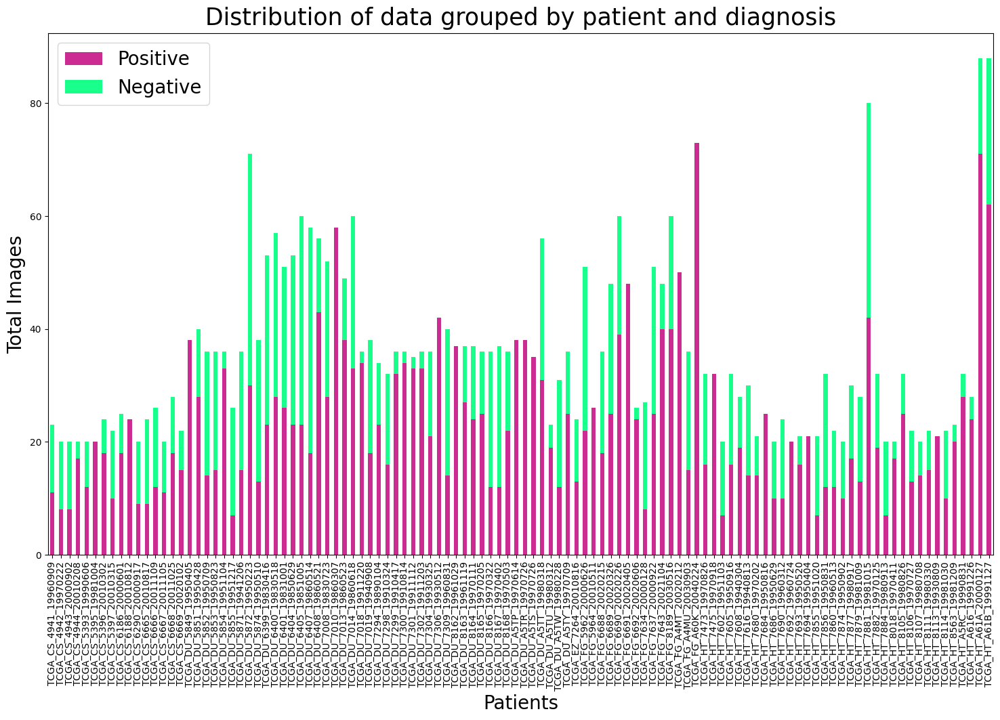

In [22]:
patients_by_diagnosis = df.groupby(['patient', 'diagnosis'])['diagnosis'].size().unstack().fillna(0)
patients_by_diagnosis.columns = ["Positive", "Negative"]

# Plot
ax = patients_by_diagnosis.plot(kind='bar',stacked=True,
                                figsize=(18, 10),
                                color=["mediumvioletred", "springgreen"],
                                alpha=0.9)
ax.legend(fontsize=20);
ax.set_xlabel('Patients',fontsize = 20)
ax.set_ylabel('Total Images', fontsize = 20)
ax.set_title("Distribution of data grouped by patient and diagnosis",fontsize = 25, y=1.005)
plt.savefig('./outputs/patient_diagnosis_distribution.pdf', format='pdf')
plt.show()

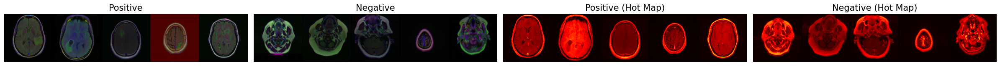

In [23]:
# Sample images by diagnosis
sample_yes_df = df[df["diagnosis"] == 1].sample(5).image_path.values
sample_no_df = df[df["diagnosis"] == 0].sample(5).image_path.values

# Load and resize images
sample_imgs = []
for yes_path, no_path in zip(sample_yes_df, sample_no_df):
    yes = cv2.imread(yes_path)
    no = cv2.imread(no_path)

    if yes is not None and no is not None:
        yes = cv2.resize(yes, (IMG_SIZE, IMG_SIZE))
        no = cv2.resize(no, (IMG_SIZE, IMG_SIZE))
        sample_imgs.extend([yes, no])

# Stack horizontally for display
sample_yes_arr = np.hstack(sample_imgs[::2])
sample_no_arr = np.hstack(sample_imgs[1::2])

# Create figure and subplots
fig, axes = plt.subplots(1, 4, figsize=(24, 6))

# Original color images
axes[0].imshow(cv2.cvtColor(sample_yes_arr, cv2.COLOR_BGR2RGB))
axes[0].set_title("Positive", fontsize=15)
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(sample_no_arr, cv2.COLOR_BGR2RGB))
axes[1].set_title("Negative", fontsize=15)
axes[1].axis("off")

# Grayscale + colormap
axes[2].imshow(sample_yes_arr[:, :, 0], cmap="hot")
axes[2].set_title("Positive (Hot Map)", fontsize=15)
axes[2].axis("off")

axes[3].imshow(sample_no_arr[:, :, 0], cmap="hot")
axes[3].set_title("Negative (Hot Map)", fontsize=15)
axes[3].axis("off")

# Add annotations
# fig.suptitle("Brain MRI Images for Brain Tumor Detection\nLGG Segmentation Dataset",
#              y=1.05, fontsize=24, weight="bold")

# plt.figtext(0.27, 0.92, "Original", fontsize=18, ha="center")
# plt.figtext(0.74, 0.92, "With Hot Colormap", fontsize=18, ha="center")

# Save and show
plt.tight_layout()
plt.savefig("./outputs/sample_images_analysis.pdf", format='pdf')
plt.show()


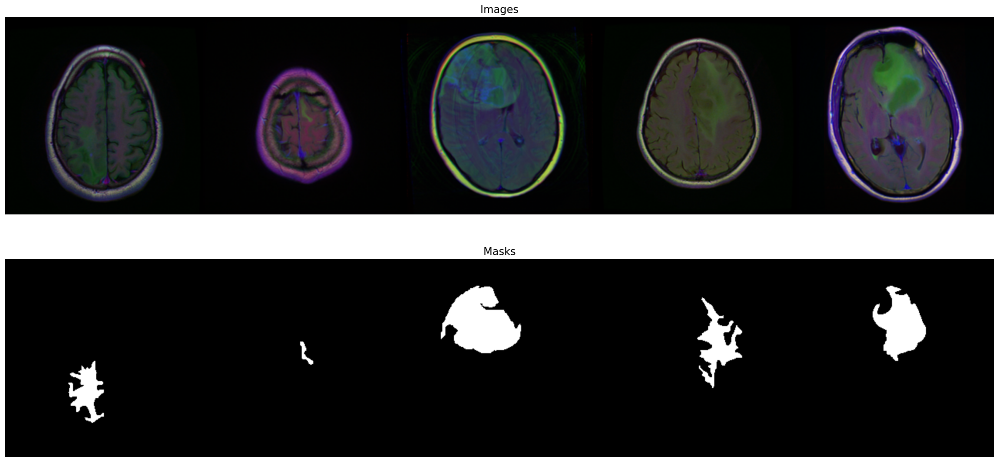

In [24]:

sample_df = df[df["diagnosis"] == 1].sample(5).values

sample_imgs = []
sample_masks = []

for data in sample_df:
    img = cv2.imread(data[1])  # image_path
    mask = cv2.imread(data[2], cv2.IMREAD_GRAYSCALE)  # mask_path

    if img is not None and mask is not None:
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE))

        sample_imgs.append(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))  # Convert to RGB
        sample_masks.append(mask)

# Stack images horizontally
sample_imgs_arr = np.hstack(sample_imgs)
sample_masks_arr = np.hstack(sample_masks)

# Plot using subplots
fig, axes = plt.subplots(2, 1, figsize=(20, 10))

axes[0].imshow(sample_imgs_arr)
axes[0].set_title("Images", fontsize=15)
axes[0].axis("off")

axes[1].imshow(sample_masks_arr, cmap='gray')
axes[1].set_title("Masks", fontsize=15)
axes[1].axis("off")

plt.tight_layout()
plt.savefig("./outputs/sample_images_masks_analysis.pdf", format='pdf')
plt.show()

In [25]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [26]:
class BrainMriDataset(Dataset):
    def __init__(self, df, transforms):
        self.df = df
        self.transforms = transforms

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        image = cv2.imread(self.df.iloc[idx, 1])
        mask = cv2.imread(self.df.iloc[idx, 2], 0)
        mask = (mask > 127).astype(np.float32)

        augmented = self.transforms(image=image,
                                    mask=mask)

        image = augmented['image']
        mask = augmented['mask']

        # Add channel dimension to mask: (H, W) -> (1, H, W)
        if mask.dim() == 2:
            mask = mask.unsqueeze(0)

        return image, mask

### 1.b.  Transformation definition on the data:

This is one of the arguments to initialize the dataset from the above class.

In [27]:
# PATCH_SIZE = 256  # or 256 if needed

# strong_transforms = A.Compose([
#     A.RandomResizedCrop(size=(PATCH_SIZE, PATCH_SIZE)),
#     A.HorizontalFlip(p=0.5),
#     A.VerticalFlip(p=0.5),
#     A.RandomRotate90(p=0.5),
#     A.Transpose(p=0.5),
#     A.Affine(scale=(0.96, 1.04), translate_percent=0.01, rotate=0, p=0.25),

#     A.RandomBrightnessContrast(p=0.5),
#     A.RandomGamma(p=0.25),
#     A.Emboss(p=0.25),
#     A.Blur(p=0.01, blur_limit=3),

#     A.OneOf([
#         A.ElasticTransform(alpha=120, sigma=6, p=1.0),
#         A.GridDistortion(p=1.0),
#         A.OpticalDistortion(distort_limit=2.0, p=1.0),
#     ], p=0.8),

#     A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
#     ToTensorV2(),
# ])


# transforms = A.Compose([
#     A.Resize(width=PATCH_SIZE, height=PATCH_SIZE),
#     A.HorizontalFlip(p=0.5),
#     A.VerticalFlip(p=0.5),
#     A.RandomRotate90(p=0.5),
#     A.Transpose(p=0.5),
#     A.Affine(scale=(0.96, 1.04), translate_percent=0.01, rotate=0, p=0.25),

#     A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
#     ToTensorV2(),
# ])


PATCH_SIZE = 256  # or 256 if needed

strong_transforms = A.Compose([
    A.RandomResizedCrop(size=(PATCH_SIZE, PATCH_SIZE)),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Transpose(p=0.5),
    A.Affine(scale=(0.96, 1.04), translate_percent=0.01, rotate=0, p=0.25),

    A.RandomBrightnessContrast(p=0.5),
    A.RandomGamma(p=0.25),
    A.Emboss(p=0.25),
    A.Blur(p=0.01, blur_limit=3),

    A.OneOf([
        A.ElasticTransform(alpha=120, sigma=6, p=1.0),
        A.GridDistortion(p=1.0),
        A.OpticalDistortion(distort_limit=2.0, p=1.0),
    ], p=0.8),

    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])


transforms = A.Compose([
    A.Resize(width=PATCH_SIZE, height=PATCH_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Transpose(p=0.5),
    A.Affine(scale=(0.96, 1.04), translate_percent=0.01, rotate=0, p=0.25),

    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])




###1.e. DataLoader:

Lets create a dataloader now using batch size of 16. This will load 16 samples of data per batch from `dataset_train`. The parameter shuffle, if set to True (default = False) will reshuffle data at every epoch.

Reference: [https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader]


In [28]:
# Split df into train_df and val_df
train_df, val_df = train_test_split(df, stratify=df.diagnosis, test_size=0.1)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

# Split train_df into train_df and test_df
train_df, test_df = train_test_split(train_df, stratify=train_df.diagnosis, test_size=0.15)
train_df = train_df.reset_index(drop=True)

#train_df = train_df[:1000]
print(f"Train: {train_df.shape} \nVal: {val_df.shape} \nTest: {test_df.shape}")

Train: (3005, 4) 
Val: (393, 4) 
Test: (531, 4)


In [29]:

BATCH_SIZE = 8
NUM_WORKERS = 0
# train
train_dataset = BrainMriDataset(df=train_df, transforms=transforms)
train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, shuffle=True)

# val
val_dataset = BrainMriDataset(df=val_df, transforms=transforms)
val_dataloader = DataLoader(val_dataset, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, shuffle=False)

#test
test_dataset = BrainMriDataset(df=test_df, transforms=transforms)
test_dataloader = DataLoader(test_dataset, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, shuffle=False)

## Step 2:  Exploratory Data Analysis (EDA):

This step involves exploring the dataset to know more about the data. For images, visual inspection is usually the go-to approach. In addition to that, the heatmap, histogram and the shape of the images can be visualized.

Thus, Lets explore the dataset and visualize them.

torch.Size([8, 3, 256, 256]) torch.Size([8, 1, 256, 256])


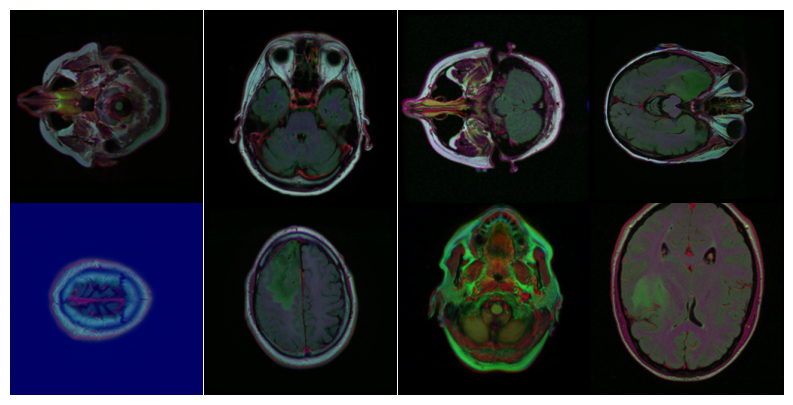

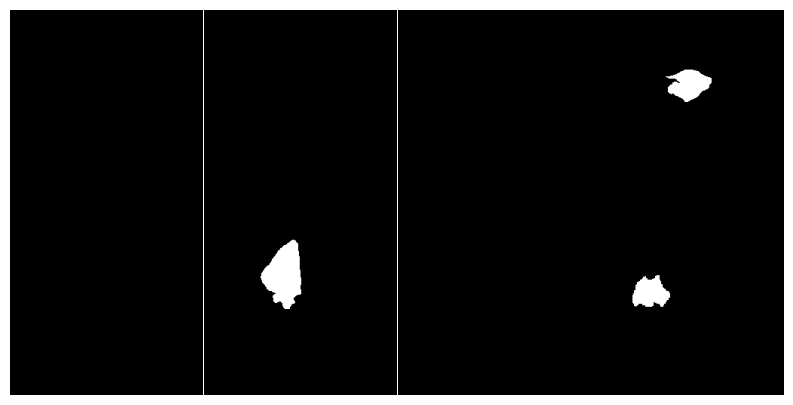

In [30]:
def show_aug(inputs, nrows=4, ncols=4, image=True):
    plt.figure(figsize=(10, 10))
    plt.subplots_adjust(wspace=0., hspace=0.)
    inputs = inputs[:nrows * ncols]  # enforce limit

    for i in range(len(inputs)):
        plt.subplot(nrows, ncols, i + 1)

        if image:
            img = inputs[i].numpy().transpose(1, 2, 0)
            mean = np.array([0.485, 0.456, 0.406])
            std = np.array([0.229, 0.224, 0.225])
            img = np.clip(img * std + mean, 0, 1)
            plt.imshow(img)
        else:
            img = inputs[i].numpy()
            if img.ndim == 3:  # e.g., shape (1, 128, 128)
                img = img.squeeze()
            plt.imshow(img, cmap="gray")
        plt.axis('off')
        plt.savefig(f"./outputs/augmented_image_{i + 1}.pdf", format='pdf')

    plt.show()



images, masks = next(iter(train_dataloader))
print(images.shape, masks.shape)

show_aug(images)
show_aug(masks, image=False)

## Step 3: Model architecture:

Segmentation task requires an encoder-decoder like architecture, because the encoder part has to capture hierarchical high-level features and the decoder part recovers the spatial details to predict pixel-wise classification.

U-Net fulfills this requirement by using an Encoer-Decoder structure with skip connections. The skip connection is an additional component that helps preserve spatial information for the decoder to recover.

Since we resized our image to 256x256, the spatial dimension changes accordingly. For that reason, let's draw the U-Net architecture with the modified image size(256x256) provided as input. (In the official paper, image of size 572x572 was supplied as an input!)  The following figure consists exactly that.


<center>

<img src="https://drive.google.com/uc?export=view&id=1Kfbx_AYq8ARdtCdiHaNYB-jeWl9MnzqH" alt="This figure depicts U-Net architecture in detail." height="1000" width="1000">

Fig: U-Net Architecture

</center>

###3.a. Contracting Path in UNet (First half of U shape):

We will be using `double convolution` (a convolution block or Dual convolution) before downsampling.
* The convolution performed for the first time in the dual convolution decreases the spatial dimension and increases the feature dimension.
* The convolution performed for the second time in the dual convolution doesn't change the feature channel size. Only the spatial size is reduced.

The spatial dimension is halved by `Max Pooling`, which is applied after double convolution.

###3.b. Expansion Path in UNet (Second half of U shape):

The `up-conv 2x2` implies the upward convolution or transpose2d convolution which increases the spatial dimension and reduces the feature channel dimension.

The decoder part also uses `double convolution` but here the operation is reverse to that of Encoder. i.e The goal is to increase the spatial dimension and reduce the feature dimension.

The final part consists of convolution using `1x1` kernel size, which doesn't change the spatial dimension. The final number of channels is specified as the parameter 'output_channels`. For example, if the segmentation map is to be made grayscale, then specify output_channels=1 in the parameter of the final 1x1 convolution.





In [31]:
import torch
import torch.nn as nn
import torchvision

Lets create a function called double_convolution which can be resued in the UNet architecture.

As per the PyTorch documentation, various methods and their corresponding arguments are listed below:


1. `torch.nn.Conv2d(in_channels, out_channels, kernel_size, stride=1, padding=0, dilation=1, groups=1, bias=True, padding_mode='zeros', device=None, dtype=None)`

2. `torch.nn.BatchNorm2d(num_features, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True, device=None, dtype=None)`

3. `torch.nn.ReLU(inplace = True)` Here the parameter is a `bool` which if true, modifies the input tensor directly without allocating new memory.  

In [32]:
def double_conv(in_channels, out_channels):
  conv = nn.Sequential(
      nn.Conv2d(in_channels, out_channels, kernel_size=3),
      nn.BatchNorm2d(out_channels),
      nn.ReLU(inplace = True),
      nn.Conv2d(out_channels, out_channels, kernel_size=3),
      nn.BatchNorm2d(out_channels),
      nn.ReLU(inplace = True),
  )

  return conv

**Note that during the concatenation operation in UNet architecture, there may be mismatch in tensor sizes**

This happens because of tensor size of down-sampling path and up-sampling path may not match always because convolution and pooling layers tend to change spatial dimension.
We can:
1. Either do padding in convolution and then concatenate
2. Or crop and concatenate.

Lets create a function for cropping the spatial dimensions.

In [33]:
import torch.nn.functional as F

In [34]:
# def center_crop(enc_feature, dec_feature):
#   _, _, h, w = dec_feature.size()
#   enc_feature = F.interpolate(enc_feature, size=(h,w), mode="bilinear", align_corners=False)
#   return enc_feature

In [35]:
def center_crop(enc_feature, dec_feature):
    _, _, h, w = dec_feature.size()  # Get the height and width of the decoder feature map
    enc_feature = torchvision.transforms.CenterCrop([h, w])(enc_feature)  # Crop encoder feature
    return enc_feature

Lets create the Model Architecture now.

There are 4 main units:
1. Encoder: Double convolution with increasing channels
2. Downsampling: Maxpooling

3. Upsampling: Transpose Convolution
4. Decoder: (Concatenation and then) Double convolution with decreasing channels

**Note that since `double_conv` and `center_crop` are not static functions inside the class, we call it without using self.**

In [36]:
class UNet(nn.Module):
  def __init__(self, in_channels, out_channels):
    super(UNet,self).__init__()

    self.enc1 = double_conv(in_channels, 64)
    self.enc2 = double_conv(64,128)
    self.enc3 = double_conv(128,256)
    self.enc4 = double_conv(256,512)
    self.enc5 = double_conv(512,1024)

    self.pool = nn.MaxPool2d(kernel_size = 2, stride = 2)

    self.trans1 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
    self.dec1 = double_conv(1024,512)
    self.trans2 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
    self.dec2 = double_conv(512,256)
    self.trans3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
    self.dec3 = double_conv(256,128)
    self.trans4 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
    self.dec4 = double_conv(128,64)

    self.out = nn.Conv2d(64, out_channels, kernel_size = 1)


  def forward(self, x):
    x1 = self.enc1(x)
    x2 = self.enc2(self.pool(x1))
    x3 = self.enc3(self.pool(x2))
    x4 = self.enc4(self.pool(x3))
    x5 = self.enc5(self.pool(x4))

    x = self.trans1(x5)
    x = center_crop(x,x4)
    x = torch.cat([x,x4], dim=1)
    x = self.dec1(x)

    x = self.trans2(x)
    x = center_crop(x,x3)
    x = torch.cat([x,x3], dim=1)
    x = self.dec2(x)

    x = self.trans3(x)
    x = center_crop(x,x2)
    x = torch.cat([x,x2], dim=1)
    x = self.dec3(x)

    x = self.trans4(x)
    x = center_crop(x,x1)
    x = torch.cat([x,x1], dim=1)
    x = self.dec4(x)

    x = self.out(x)

    return(x)

###3.c. Model Instantiation:

The number of in_channels and out_channels have to be specified because the constructor in the above class requires these.

In [37]:
model = UNet(in_channels=3, out_channels=1)

In [38]:
model

UNet(
  (enc1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
  )
  (enc2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1))
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
  )
  (enc3): Sequential(
    (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1))
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(256, 256, kernel_

###3.d. Model Visualization:

In [39]:
# from torchviz import make_dot

# sample_input = torch.rand(1,3,256,256)  # b,c,h,w
# output = model(sample_input)
# dot = make_dot(output, params = dict(model.named_parameters()))
# dot.format = 'png'
# dot.render('model_architecture')

# from IPython.display import Image
# Image('model_architecture.png')

## Step 4: Model Training:

4.a. Prerequisites for the training loop:

- Method to stop the training : Early stopping
- Metric: Dice coefficient

Early stoppping:

This is needed to stop the training if the validation accuracy doesn't increase for a while, or the validation loss doesn't decrease for a while. Also we need to save the model if the dice score improves.

In [40]:
save_path = './outputs/'
os.makedirs(save_path, exist_ok=True)

In [41]:
class EarlyStoppingAndSave:
    def __init__(self, patience=5, min_delta=0.001, save_path=None, model=None):
        self.patience = patience
        self.min_delta = min_delta
        self.best_val_loss = None
        self.best_dice_score = None
        self.counter = 0
        self.early_stop = False
        self.save_path = save_path
        self.model = model

    def check_early_stop(self, val_loss, dice_score, epoch):
        if self.best_val_loss is None:
            self.best_val_loss = val_loss
            self.best_dice_score = dice_score
            self.save_model(epoch)
        elif (val_loss > self.best_val_loss - self.min_delta) and (dice_score <= self.best_dice_score + self.min_delta):
            self.counter += 1
            if self.counter >= self.patience:
                print(f"Early stopping activated! Best Val Loss: {self.best_val_loss}, Best Dice Score: {self.best_dice_score}")
                self.early_stop = True
        else:
            self.best_val_loss = min(val_loss, self.best_val_loss)
            self.best_dice_score = max(dice_score, self.best_dice_score)
            self.counter = 0
            self.save_model(epoch)

    def save_model(self, epoch):
        # Save the model if it's the best one so far
        model_save_path = os.path.join(self.save_path, f'best_model_epoch_{epoch+1}.pth')
        torch.save(self.model.state_dict(), model_save_path)
        print(f"Model saved at {model_save_path}")

Lets also calculate the dice coefficient.

In [42]:
# Dice Coefficient Calculation
def dice_coefficient(preds, targets, threshold=0.5):
    preds = (preds > threshold).float()  # Binarize predictions
    intersection = (preds * targets).sum()
    dice = (2. * intersection) / (preds.sum() + targets.sum() + 1e-6)
    return dice

###4.b. Training Loop:

The training loop consists of many iterations of prediction and backpropagation for the given number of epochs.

In [43]:
from tqdm import tqdm

In [44]:
# Training for one epoch
def train_one_epoch(model, train_dataloader, optimizer, criterion, device):
    model.train()
    running_train_loss = 0.0
    num_train_samples = 0.0

    for image, mask in tqdm(train_dataloader, desc="Training", leave=False):
        image, mask = image.to(device), mask.to(device)
        optimizer.zero_grad()
        output = model(image)
        output = F.interpolate(output, size=mask.shape[2:], mode='bilinear', align_corners=False)
        loss = criterion(output, mask)
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * image.size(0)
        num_train_samples += image.size(0)

    avg_train_loss = running_train_loss / num_train_samples
    return avg_train_loss

###4.c. Validation loop:

Similar to training loop but model is in evaluation mode, and no gradient calculation is done.

In [45]:
# Validation for one epoch, returns loss and dice score
def validate_one_epoch(model, val_dataloader, criterion, device):
    model.eval()
    running_val_loss = 0.0
    running_dice_score = 0.0
    num_val_samples = 0.0

    with torch.no_grad():
        for image, mask in tqdm(val_dataloader, desc="Validation", leave=False):
            image, mask = image.to(device), mask.to(device)
            output = model(image)
            output = F.interpolate(output, size=mask.shape[2:], mode='bilinear', align_corners=False)
            loss = criterion(output, mask)
            dice_score = dice_coefficient(output, mask)

            running_val_loss += loss.item() * image.size(0)
            running_dice_score += dice_score.item() * image.size(0)
            num_val_samples += image.size(0)

    avg_val_loss = running_val_loss / num_val_samples
    avg_dice_score = running_dice_score / num_val_samples

    return avg_val_loss, avg_dice_score

### Main Loop:

This is the outer loop (that runs for certain epochs) that does the following:
1. Calls both functions (train and validation loop) in each epoch.
  * Executes inner loop by iterating over dataloader.
2. Keep track of both losses, and dice score to be plotted later.

In [46]:
# Main training function with early stopping and saving model
def train_model(model, train_dataloader, val_dataloader, optimizer, criterion, num_epochs, device, patience=5):
    train_losses = []
    val_losses = []
    dice_scores = []
    early_stopping = EarlyStoppingAndSave(patience=patience, save_path=save_path, model=model)

    for epoch in tqdm(range(num_epochs), desc="Epochs"):
        train_loss = train_one_epoch(model, train_dataloader, optimizer, criterion, device)
        train_losses.append(train_loss)

        val_loss, dice_score = validate_one_epoch(model, val_dataloader, criterion, device)
        val_losses.append(val_loss)
        dice_scores.append(dice_score)

        print(f"Epoch [{epoch+1}/{num_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, Dice Score: {dice_score:.4f}")

        # Check for early stopping and save model if the dice score improves
        early_stopping.check_early_stop(val_loss, dice_score, epoch)

        if early_stopping.early_stop:
            print("Training stopped early.")
            break

    return train_losses, val_losses, dice_scores

###4.d. Hyperparameters and Optimizers:

Lets specify learning rate, number of epochs, optimizer, and loss function ( `Binary CrossEntropy Loss`).

In [47]:
learning_rate = 0.001
num_epochs = 30    # a large number to facilitate early stopping

In [48]:
criterion = nn.BCEWithLogitsLoss()

In [49]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


Lets not forget to load some of the tensors (that may have been loaded in CPU) to the GPU.

In [50]:
model = model.to(device)

In [51]:
import torch.optim as optim

Training the model by calling the above function:

In [52]:
train_losses, val_losses, dice_scores = train_model(
    model=model,
    train_dataloader=train_dataloader,
    val_dataloader=val_dataloader,
    optimizer=optim.Adam(model.parameters(), lr=learning_rate),
    criterion=criterion,
    num_epochs=num_epochs,
    device=device,
    patience=10  # Patience for early stopping
)

Training: 100%|██████████| 376/376 [01:55<00:00,  3.66it/s]
                                                           
Epochs:   3%|▎         | 1/30 [02:03<59:40, 123.45s/it]    

Epoch [1/30], Train Loss: 0.1177, Val Loss: 0.0342, Dice Score: 0.4104
Model saved at ./outputs/best_model_epoch_1.pth



Training: 100%|██████████| 376/376 [01:27<00:00,  4.72it/s]
                                                           
Epochs:   7%|▋         | 2/30 [03:36<49:19, 105.69s/it]    

Epoch [2/30], Train Loss: 0.0281, Val Loss: 0.0226, Dice Score: 0.5553
Model saved at ./outputs/best_model_epoch_2.pth



Training: 100%|██████████| 376/376 [01:27<00:00,  4.82it/s]
                                                           
Epochs:  10%|█         | 3/30 [05:09<44:55, 99.84s/it]     

Epoch [3/30], Train Loss: 0.0225, Val Loss: 0.0198, Dice Score: 0.5228
Model saved at ./outputs/best_model_epoch_3.pth


... (52 outputs left out)


Training: 100%|██████████| 376/376 [01:28<00:00,  4.76it/s]
                                                           
Epochs:  97%|█████████▋| 29/30 [45:18<01:33, 93.05s/it]    

Epoch [29/30], Train Loss: 0.0096, Val Loss: 0.0099, Dice Score: 0.7525
Model saved at ./outputs/best_model_epoch_29.pth



Training: 100%|██████████| 376/376 [01:28<00:00,  4.71it/s]
                                                           
Epochs: 100%|██████████| 30/30 [46:52<00:00, 93.73s/it]    

Epoch [30/30], Train Loss: 0.0094, Val Loss: 0.0084, Dice Score: 0.7085
Model saved at ./outputs/best_model_epoch_30.pth


Lets visualize the loss curve:

In [53]:
def smooth_curve(points, factor=0.8):
    smoothed_points = [points[0]]  # Initialize with first point
    for point in points[1:]:
        smoothed_points.append(smoothed_points[-1] * factor + point * (1 - factor))
    return smoothed_points

In [54]:
def plot_loss_curve(train_losses, val_losses):
    epochs = range(1, len(train_losses) + 1)
    smoothed_val_losses = smooth_curve(val_losses)

    plt.figure(figsize=(10, 6))
    plt.plot(epochs, train_losses, 'b', label='Training Loss')
    plt.plot(epochs, smoothed_val_losses, 'r', label='Validation Loss (smoothed)')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.ylim(0, max(train_losses + val_losses) * 1.1)
    plt.savefig('./outputs/loss_curve.pdf', format='pdf')
    plt.show()

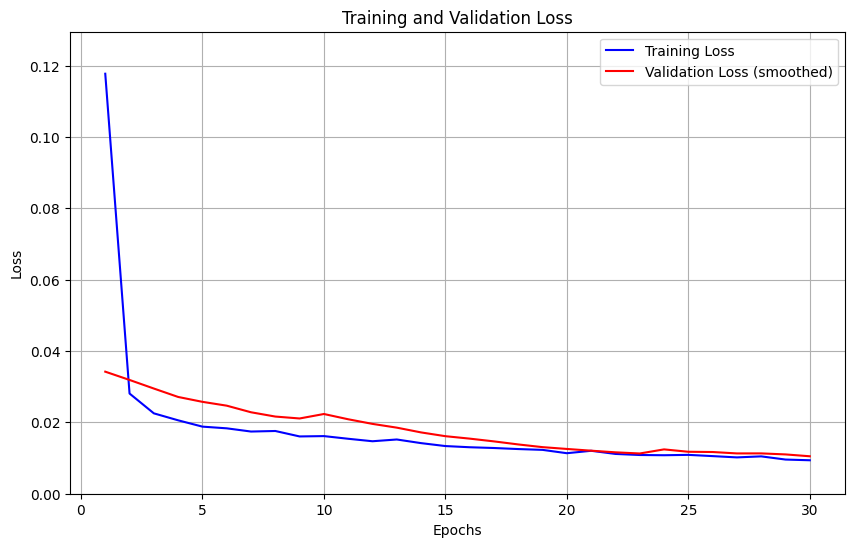

In [55]:
plot_loss_curve(train_losses, val_losses)

## Model Evaluation:

Evaluation refers to the use of different evaluation metrics to understand the model's performance. It is usually done in the `holdout dataset` or `test dataset`.

In our case, the binary classification of pixels is done in order to create a ground truth mask. Thus, model may perform any of the four cases:
- Predict actual positive class as positive (True Positive or TP)
- Predict actual negative class as positive (False Positive or FP)
- Predict actual positive class as negative (False Negative or FN)
- Predict actual negative class as negative (True Positive or TN)

This can be made clear with the following figure:


<center>

<img src="https://drive.google.com/uc?export=view&id=1IUxU2QcIZ6bLfH_FaAld0WTwsnkX26WW" alt="Contains classification metric" height="400" width="800">

Fig: Understanding confusion matrix in Binary classification task

</center>

In the above figure, the first rectangle (blue without overlap) represent the actual positive class (which may be predicted by model as positive or negative). And the second rectangle (yellow without overlap) represent the predicted positive class (which may include the actual positive or negative class).
- The overlapping green region is an actual positive, also predicted by model as positve. So it is TP.
- The blue region is an actual positive but the model didn't predict it to be positive (i.e. model predicted it to be negative). So, it is FN.
- The yellow region is an actual negative but the model classified it as positive. So, it is FP
- The remaining white region is an actual negative, and the model classified it as negative. So, it is TN.

## Evaluation metrics:

1. $Precision = {TP \over TP+FP}$
  
- Tells us how many of the positive predictions made by the model are actually correct.
- Also called accuracy for positive class prediction.
- Important when minimizing false positives out of all positive predictions is important.
- Example: In sentencing a suspect to a prison, we want to be entirely sure if s/he is guilty because falsely incarcenating someone has a very high cost. (The sole principle of Justice system is that it is considered better to leave out 100 criminals than to falsely accuse  1 innocent person)

\

2. $Recall (Sensitivity) (TPR) = {TP \over TP+FN}$

- Tells us how much of the actual positive instances are correctly identified by the model.
- Also called confidence of the model in predicting positive instances.
- Suitable when we want to identify as many positive samples as possible.
- In disease diagnostics, we want to find all risks even though the cases are not that serious. (Even if a healthy person is identified as a risk, he can always go to an actual doctor and rerun the tests. It's more dangerous to leave out the possible risky patients)

\

3. $Accuracy = {Correct-prediction \over Total-samples} = {TP+TN \over TP+FP+FN+TN}$

- Tells us if the model classified samples (of both classes) correctly.
- Also called `RAND Index` or Combined accuracy.
- Not suitable for imbalanced dataset (datasets where there are more samples in 1 class than the others)

\

4. $Specificity(TNR) = {TN \over FP+TN}$

- Tells us how much actual negative instances are correctly identified by the model. `Similar to recall, but for negative class`
- Suitable when identifying negative items are important.
- Example: (Refer to example for Precision): We want to maximize the chance of classifying innocent people as innocent. That way True Negatives (TN) will be identified, ensuring lower false incarcenation (Low False positives).

\

5. $FPR = {FP \over FP + TN}$

- Tells us how much actual negatives are falsely identified by the model.
- Also called model's inaccuracy in classifying negative as negative,
- Suitable to find (and thus minimize) false positives (FP)
-  Example: (Refer to example for Precision)

\

**Note that FPR and TPR are used to plot AUC curve**
- FPR in X-axis, TPR(sensitivity) in Y-axis.
- If the area under the curve is high, the model is better ar detecting True Positives (TP) and mminimizing False Positives (FP).

\

6.  $IoU = {TP \over TP + FP + FN}$

- Also called Jaccard index or Intersection over Union.
- It is the area of the overlap over union (of the predicted segmentation and the ground truth.)
- Gives equal weightage to TP and FP. (If the model has high FP, the score decreases. Thus False positives are penalized.)

\

7.  $F1 Score = {2 (Precision * Recall) \over Precision + Recall}$
- Maximizes both Precision and Recall independently:
  
  - If precision is low, the model's accuracy is low for positive class. (High FP, high FPR)
  - If recall is low, the model is leaving out large samples of actual positive class. (Actual positives might be predicted as negatives, so high FN, high FNR)

- Harmonic mean gives more weight to the lower values. Thus if either of Recall or Precision is low, the harmomic mean will be high. Thus the only way to maximize F1 score is to maximize both precision as well as recall.

\

* $ Dice Coefficient = {2 * TP \over 2*TP + FP + FN}$
  - Same thing as F1 Score
  - More weight given to TP, so even if the model has high FP, the score doesn't change as much. Thus False positives are not penalized like in IoU. (Minimizing FP is not the biggest concern, but maximizing TP is)


## Model performance:

Lets initialize the model architecture to load the trained weights

In [56]:
model = UNet(in_channels=3, out_channels=1)

The trained model is saved in Google drive, so we load the saved model as:

In [57]:
model.load_state_dict(torch.load('./outputs/best_model_epoch_5.pth'))

<All keys matched successfully>

Lets load the tensors to the current device.

To make an inference, we put the model in evaluation mode, and disable the gradient calculation.

* `model.eval()` is done to change the behavior of layers such as 'BatchNorm' and 'Dropout'. For example, Our model 'U-Net' consists of dual convolution, which consists of batchnorm2d layers. The behaviour of this layer has to be changed to ensure it predicts correctly during evaluation.

* `torch.no_grad()` is done to prevent PyTorch from storing gradients, thus freeing up memory.

In [58]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [59]:
model = model.to(device)
model.eval()

UNet(
  (enc1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
  )
  (enc2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1))
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
  )
  (enc3): Sequential(
    (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1))
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(256, 256, kernel_

In [60]:
def dice_score(preds, targets):
    smooth=1e-6
    intersection = (preds * targets).sum()
    return (2. * intersection + smooth) / (preds.sum() + targets.sum() + smooth)

In [ ]:
def display_image_gt_pred(image_tensor, ground_truth_tensor, predictions_tensor, dice_score, idx, n=1):
    image_pil = TF.to_pil_image(image_tensor)
    ground_truth_pil = TF.to_pil_image(ground_truth_tensor)
    predictions_pil = TF.to_pil_image(predictions_tensor)

    fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(24, 6))

    axes[0].imshow(image_pil)
    axes[0].set_xlabel('Image')
    axes[0].axis('off')

    axes[1].imshow(ground_truth_pil, cmap='gray')
    axes[1].set_xlabel('Ground Truth')
    axes[1].axis('off')

    axes[2].imshow(predictions_pil, cmap='gray')
    axes[2].set_xlabel('Prediction')
    axes[2].axis('off')

    # Histogram of image only (all 3 channels merged)
    img_arr = np.array(image_pil).ravel()
    bins = 32
    axes[3].hist(img_arr, bins=bins, color='blue', alpha=0.7, label='Image')
    axes[3].set_xlabel('Image Histogram')
    axes[3].legend()
    axes[3].set_yticks([])

    plt.tight_layout()
    # Plot histograms for each channel separately with distinct colors
    img_arr = np.array(image_pil)
    bins = 32
    colors = ['red', 'green', 'blue']
    labels = ['Red', 'Green', 'Blue']
    for i in range(3):
        axes[3].hist(img_arr[..., i].ravel(), bins=bins, color=colors[i], alpha=0.5, label=labels[i])
    axes[3].set_xlabel('Image Histogram')
    axes[3].legend()
    axes[3].set_yticks([])

    plt.savefig(f"./outputs/image_gt_pred_{idx + 1}.pdf", format='pdf')
    plt.show()


To sort and extract the best and worst instances, lets create a list called `results`. It is not just a simple list, but contains dictionaries. Each dictionary contains the following key value pairs:
1. image: original image tensor of shape [c,h,w]
2. ground truth: tensor of gt mask of shape [h,w]
3. prediction: tensor of mask tensor (after applying sigmoid and thresholding, to creata a binary mask)
4. dice score: a float value of dice score between predicted mask and ground truth mask.

In [62]:
# Initialize list to store results
results = []

# Perform inference and store images, ground truth, predictions, and dice scores
with torch.no_grad():
    for idx, (images, ground_truths) in enumerate(val_dataloader):
        images = images.to(device)
        ground_truths = ground_truths.to(device)

        # Forward pass through the model
        outputs = model(images)
        outputs = F.interpolate(outputs, size=ground_truths.shape[2:], mode='bilinear', align_corners=False)

        # Apply sigmoid to get probabilities and binarize predictions (threshold at 0.5)
        predictions = torch.sigmoid(outputs)
        predictions = (predictions > 0.5).float()

        # Compute dice score for each sample in the batch
        for i in range(len(images)):
            current_dice = dice_score(predictions[i], ground_truths[i])

            # Store image, ground truth, prediction, and dice score in the results list
            results.append({
                'image': images[i].cpu(),
                'ground_truth': ground_truths[i].cpu(),
                'prediction': predictions[i].cpu(),
                'dice_score': current_dice
            })

In [91]:
smooth = 1e-6

total_inter, total_union = 0.0, 0.0         # for dataset‐wide IoU
total_correct, total_pixels = 0, 0          # for dataset‐wide pixel accuracy

with torch.no_grad():
    for images, masks in val_dataloader:
        images, masks = images.to(device), masks.to(device)
        outputs = model(images)
        outputs = F.interpolate(outputs,
                                size=masks.shape[2:],
                                mode='bilinear',
                                align_corners=False)

        # --- binarize predictions ---
        preds_bin = (torch.sigmoid(outputs) > 0.5).float()
        
        # --- flatten for IoU ---
        p_flat = preds_bin.view(preds_bin.size(0), -1)
        t_flat = masks.view(masks.size(0), -1).float()
        
        # --- accumulate intersection & union per batch ---
        intersection = (p_flat * t_flat).sum(dim=1)
        union = p_flat.sum(dim=1) + t_flat.sum(dim=1) - intersection
        total_inter += intersection.sum().item()
        total_union += union.sum().item()
        
        # --- accumulate correct pixels & total pixels ---
        total_correct += (preds_bin == masks).sum().item()
        total_pixels += masks.numel()

# --- final metrics ---
avg_iou = (total_inter + smooth) / (total_union + smooth)
overall_acc = total_correct / total_pixels

print(f"Average IoU over val set:     {avg_iou:.4f}")
print(f"Overall pixel accuracy:       {overall_acc:.4f}")


Average IoU over val set:     0.5146
Overall pixel accuracy:       0.9935


In [63]:
# Filter results for positive instances (ground truth has tumor)
positive_results = []
negative_results = []

for result in results:
    # Check if ground truth has positive pixels (tumor present)
    if result['ground_truth'].sum() > 0:
        positive_results.append(result)
    else:
        negative_results.append(result)

# Sort both lists by dice score
positive_results = sorted(positive_results, key=lambda x: x['dice_score'])
negative_results = sorted(negative_results, key=lambda x: x['dice_score'])

print(f"Total positive instances: {len(positive_results)}")
print(f"Total negative instances: {len(negative_results)}")

# For backward compatibility, keep the original sorted results
results = sorted(results, key=lambda x: x['dice_score'])

Total positive instances: 137
Total negative instances: 256


Since the results has the dice scores in ascending order, the last 5 dice scores are the highest.


Top 5 Best Predictions (Positive instances only):


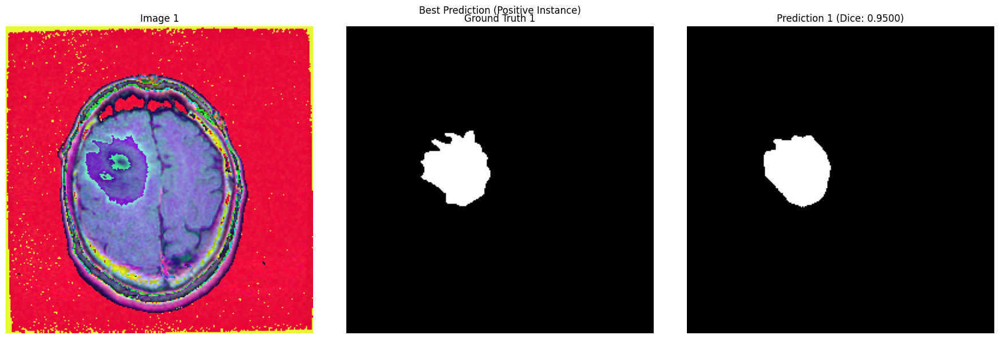

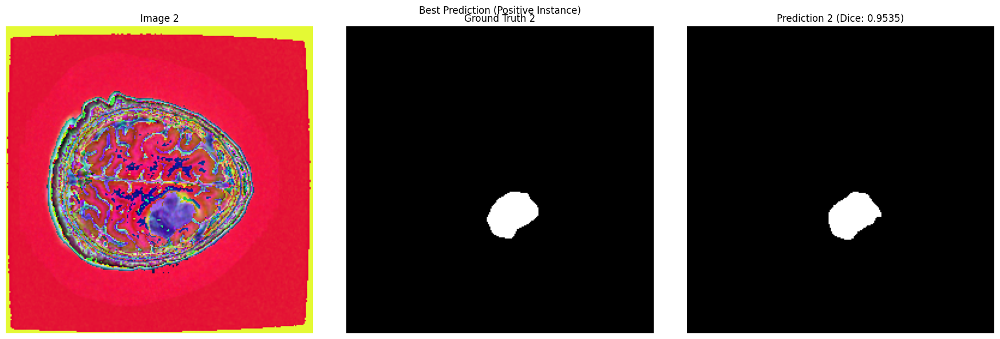

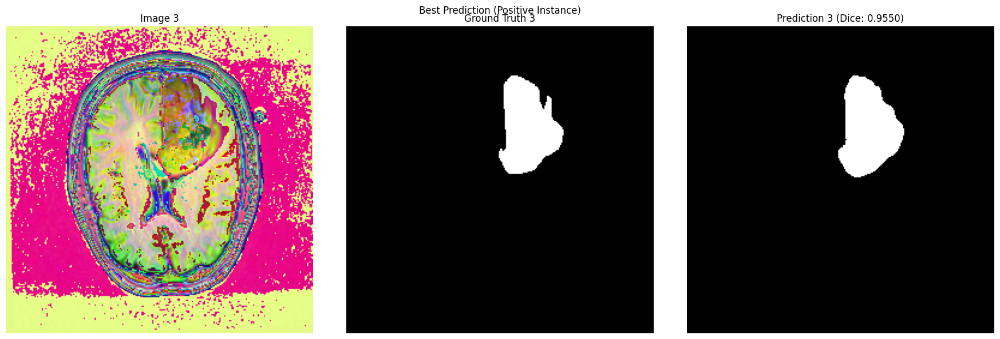

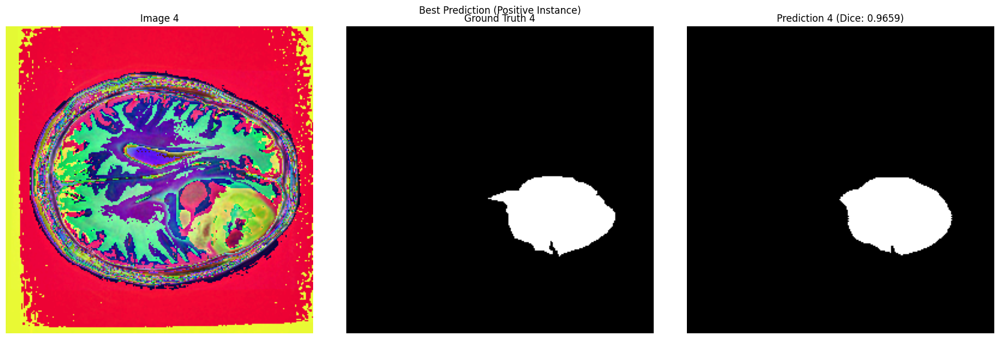

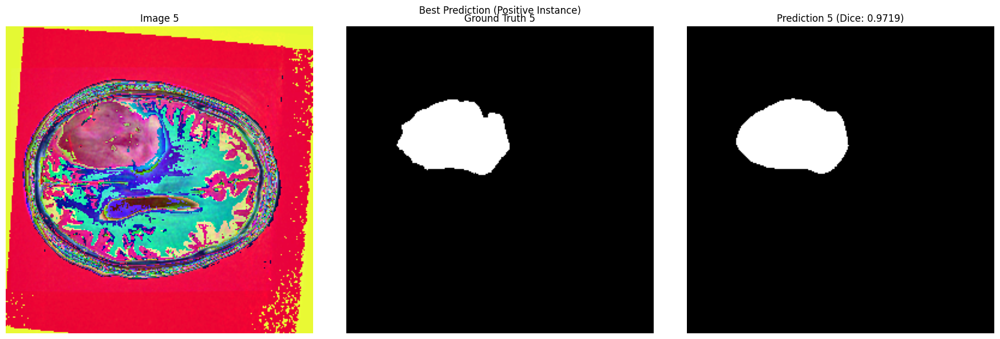

In [64]:
print("\nTop 5 Best Predictions (Positive instances only):")
if len(positive_results) >= 5:
    for idx, result in enumerate(positive_results[-5:]):
        display_image_gt_pred(result['image'], result['ground_truth'], result['prediction'],
                              result['dice_score'], idx, title='Best Prediction (Positive Instance)')
else:
    print(f"Only {len(positive_results)} positive instances available:")
    for idx, result in enumerate(positive_results):
        display_image_gt_pred(result['image'], result['ground_truth'], result['prediction'],
                              result['dice_score'], idx, title='Best Prediction (Positive Instance)')


Top 5 Worst Predictions (Positive instances only):


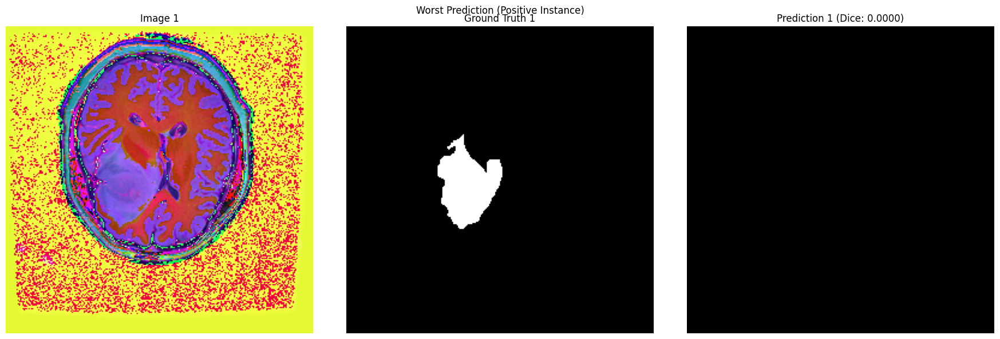

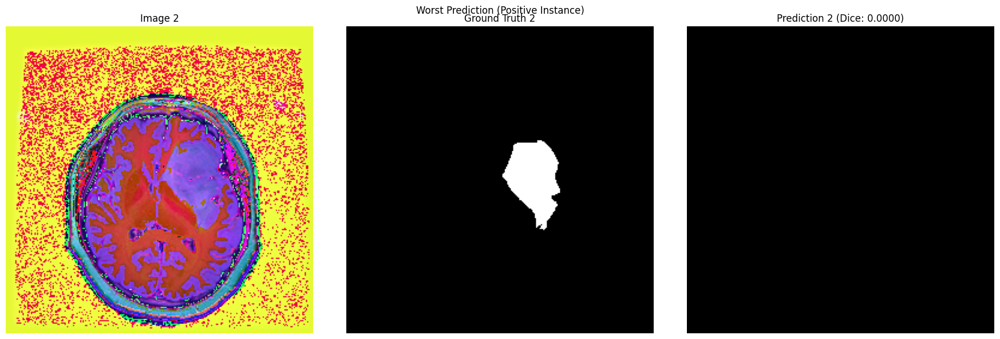

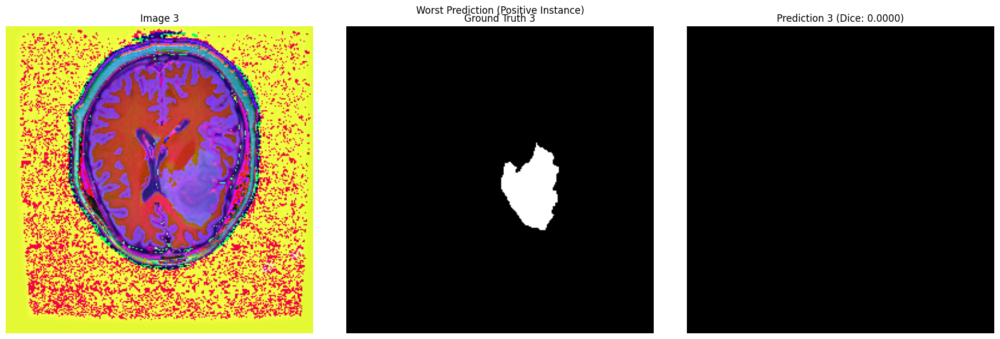

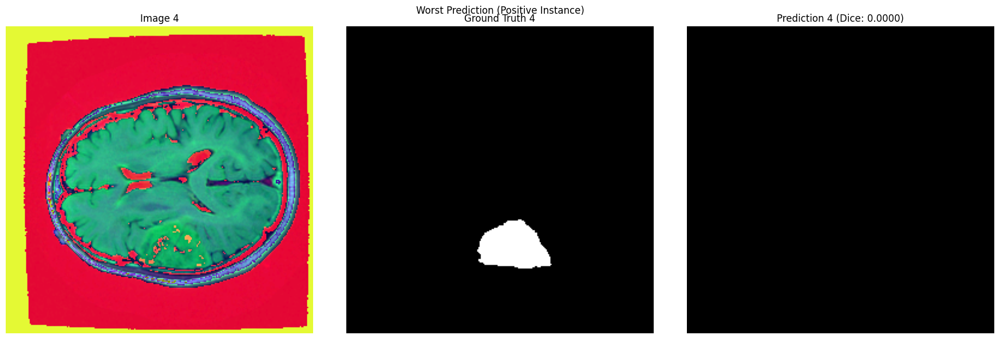

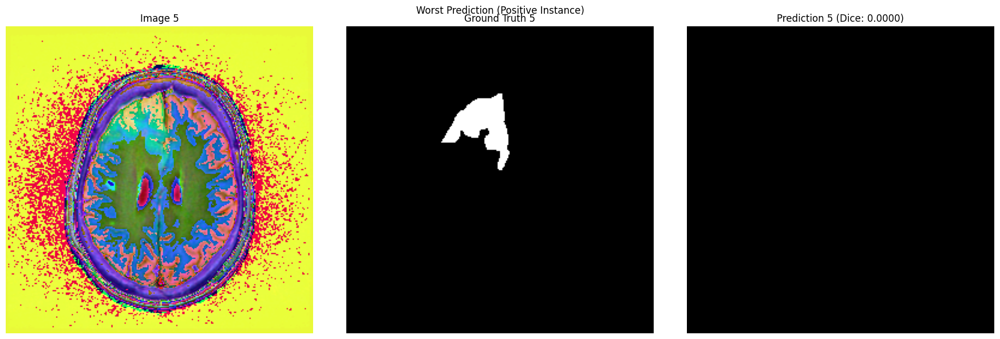

Top 5 Worst Predictions (All instances):


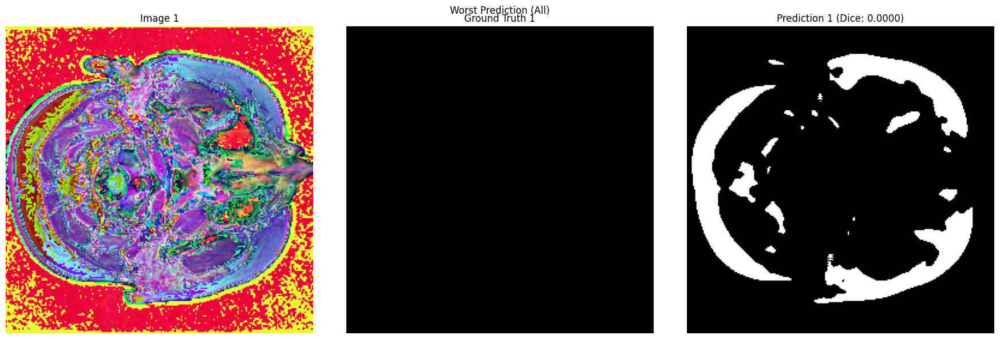

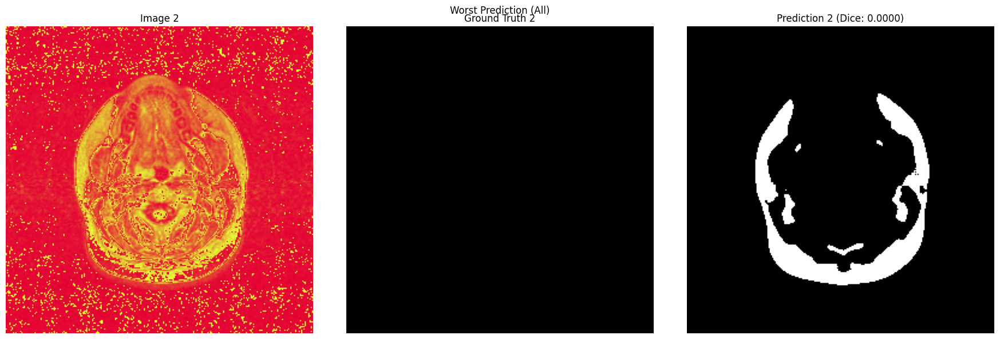

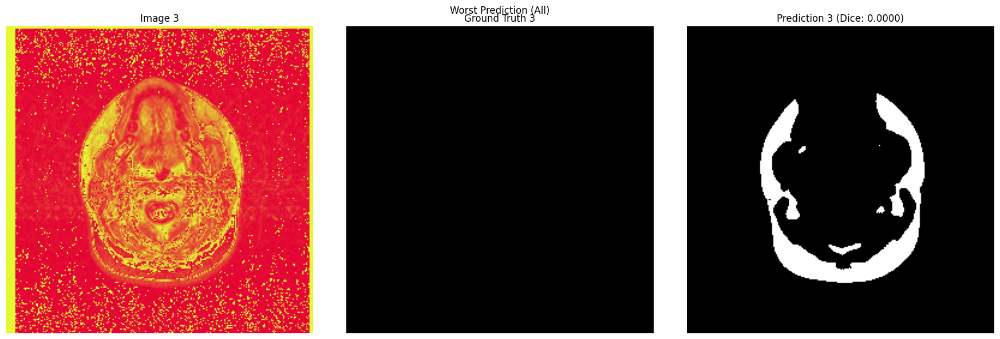

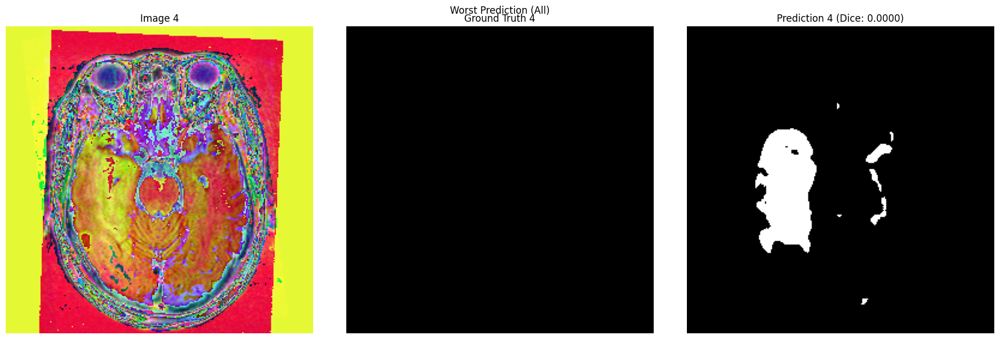

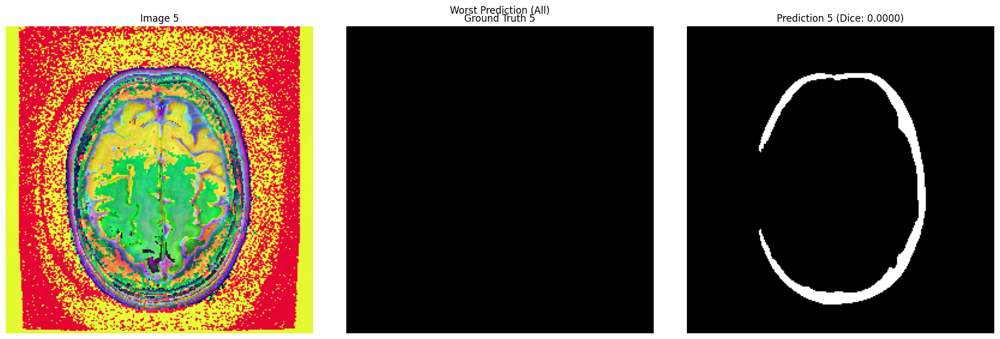

In [65]:
print("Top 5 Worst Predictions (Positive instances only):")
if len(positive_results) >= 5:
    for idx, result in enumerate(positive_results[:5]):
        display_image_gt_pred(result['image'], result['ground_truth'], result['prediction'],
                              result['dice_score'], idx, title='Worst Prediction (Positive Instance)')
else:
    print(f"Only {len(positive_results)} positive instances available:")
    for idx, result in enumerate(positive_results):
        display_image_gt_pred(result['image'], result['ground_truth'], result['prediction'],
                              result['dice_score'], idx, title='Worst Prediction (Positive Instance)')

print("Top 5 Worst Predictions (All instances):")
for idx, result in enumerate(results[:5]):
    display_image_gt_pred(result['image'], result['ground_truth'], result['prediction'],
                          result['dice_score'], idx, title='Worst Prediction (All)')


In [71]:
# Initialize list to store results
test_results = []
test_dice = 0.0
test_iou = 0.0
num_samples = 0

def iou_score(preds, targets, smooth=1e-6):
    intersection = (preds * targets).sum()
    union = preds.sum() + targets.sum() - intersection
    return (intersection + smooth) / (union + smooth)

# Perform inference and store images, ground truth, predictions, and dice scores
with torch.no_grad():
    for idx, (images, ground_truths) in enumerate(test_dataloader):
        images = images.to(device)
        ground_truths = ground_truths.to(device)

        # Forward pass through the model
        outputs = model(images)
        outputs = F.interpolate(outputs, size=ground_truths.shape[2:], mode='bilinear', align_corners=False)

        # Apply sigmoid to get probabilities and binarize predictions (threshold at 0.5)
        predictions = torch.sigmoid(outputs)
        predictions = (predictions > 0.5).float()

        # Compute dice score and IoU for each sample in the batch
        for i in range(len(images)):
            current_dice = dice_score(predictions[i], ground_truths[i])
            current_iou = iou_score(predictions[i], ground_truths[i])
            test_dice += current_dice
            test_iou += current_iou
            num_samples += 1

            # Store image, ground truth, prediction, and dice score in the results list
            test_results.append({
                'image': images[i].cpu(),
                'ground_truth': ground_truths[i].cpu(),
                'prediction': predictions[i].cpu(),
                'dice_score': current_dice,
                'iou_score': current_iou
            })

# Calculate overall Dice and IoU
overall_dice = test_dice / num_samples if num_samples > 0 else 0
overall_iou = test_iou / num_samples if num_samples > 0 else 0
print(f"Overall Dice Score: {overall_dice:.4f}")
print(f"Overall IoU Score: {overall_iou:.4f}")

Overall Dice Score: 0.6451
Overall IoU Score: 0.6121


## Inference on Test datasets:

The images on this dataset is completely unseen by the model during the training (unlike the validation set).
The inference on test instances gives us the idea of how the model will perform in the real world data after deployment.  

Lets make the inference similarly..

In [66]:
class KvasirDataset(Dataset):
    def __init__(self, images_dir, masks_dir=None, transform=None, target_transform=None):
        self.images_dir = images_dir
        self.masks_dir = masks_dir
        self.image_filenames = sorted(os.listdir(images_dir))
        self.mask_filenames = sorted(os.listdir(masks_dir))
        self.transform = transform
        self.target_transform = target_transform

    def __len__(self):
        return len(self.image_filenames)

    def __getitem__(self, idx):
        img_path = os.path.join(self.images_dir, self.image_filenames[idx])
        mask_path = os.path.join(self.masks_dir, self.mask_filenames[idx])

        # Use PIL to open the images
        image = PilImage.open(img_path).convert("RGB")
        mask = PilImage.open(mask_path).convert("L")  # Convert mask to grayscale

        # Apply the transformations if available
        if self.transform:
            image = self.transform(image)
        if self.target_transform:
            mask = self.target_transform(mask)

        return image, mask

In [67]:
from torchvision import transforms

In [68]:
transforms1 = transforms.Compose([
    transforms.Resize((256, 256), interpolation=PilImage.NEAREST),  # Nearest neighbor for masks
    transforms.ToTensor(),
])


In [72]:
dataset = KvasirDataset(
    images_dir = "/kaggle/input/benchmark-data/benchmark_data/images",
    masks_dir = "/kaggle/input/benchmark-data/benchmark_data/masks",
    transform = transforms1,
    target_transform = transforms1)

In [73]:
from torch.utils.data import DataLoader

benchmark_dataloader = DataLoader(dataset, batch_size = 4)

In [74]:
for images, masks in benchmark_dataloader:
    print(f"Image batch shape: {images.shape}")
    print(f"Mask batch shape: {masks.shape}")
    break  # Display the first batch only

Image batch shape: torch.Size([4, 3, 256, 256])
Mask batch shape: torch.Size([4, 1, 256, 256])


In [75]:
import matplotlib.pyplot as plt
import torchvision.transforms.functional as TF
import numpy as np

def display_figures(image_tensor, mask_tensor, idx):
    image_pil = TF.to_pil_image(image_tensor)
    mask_pil = TF.to_pil_image(mask_tensor)
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.title(f"Image {idx + 1}")
    plt.imshow(image_pil)

    # plt.subplot(1, 4, 2)
    # plt.title(f"Image {idx + 1} Histogram")
    # image_np = np.array(image_pil)
    # plt.hist(image_np.ravel(), bins=256, color='blue')

    plt.subplot(1, 2, 2)
    plt.title(f"Mask {idx + 1}")
    plt.imshow(mask_pil, cmap='gray')
    plt.savefig(f"./outputs/image_mask_{idx + 1}.pdf", format='pdf')
    # plt.subplot(1, 4, 4)
    # plt.title(f"Mask {idx + 1} Histogram")
    # mask_np = np.array(mask_pil)
    # plt.hist(mask_np.ravel(), bins=256, color='blue')

    plt.show()

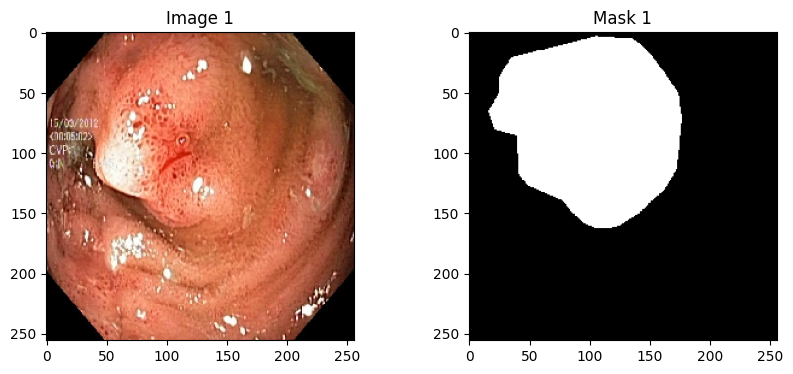

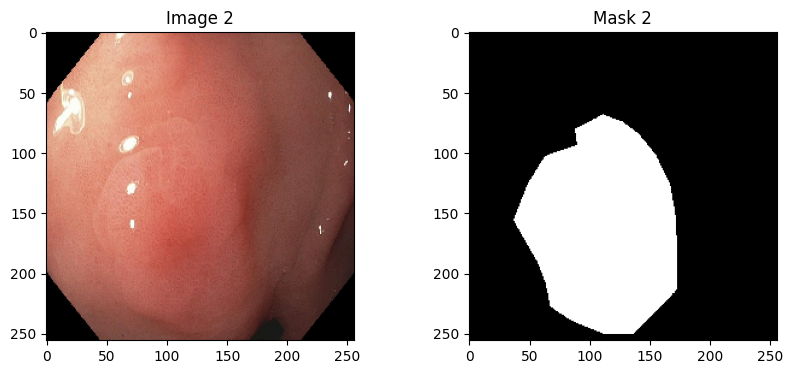

In [76]:
images, masks = next(iter(benchmark_dataloader))

for i in range(2):
    display_figures(images[i], masks[i], i)

In [77]:
model = UNet(in_channels=3, out_channels=1)

In [78]:
model.load_state_dict(torch.load('./outputs/best_model_epoch_5.pth'))

<All keys matched successfully>

In [79]:
model = model.to(device)
model.eval()

UNet(
  (enc1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
  )
  (enc2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1))
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
  )
  (enc3): Sequential(
    (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1))
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(256, 256, kernel_

In [83]:
# Initialize list to store results
bench_results = []
total_dice = 0.0
total_iou = 0.0
num_samples = 0

def iou_score(preds, targets, smooth=1e-6):
    intersection = (preds * targets).sum()
    union = preds.sum() + targets.sum() - intersection
    return (intersection + smooth) / (union + smooth)

# Perform inference and store images, ground truth, predictions, and dice scores
with torch.no_grad():
    for idx, (images, ground_truths) in enumerate(benchmark_dataloader):
        images = images.to(device)
        ground_truths = ground_truths.to(device)

        # Forward pass through the model
        outputs = model(images)
        outputs = F.interpolate(outputs, size=ground_truths.shape[2:], mode='bilinear', align_corners=False)

        # Apply sigmoid to get probabilities and binarize predictions (threshold at 0.5)
        predictions = torch.sigmoid(outputs)
        predictions = (predictions > 0.5).float()

        # Compute dice score and IoU for each sample in the batch
        for i in range(len(images)):
            current_dice = dice_score(predictions[i], ground_truths[i])
            current_iou = iou_score(predictions[i], ground_truths[i])
            total_dice += current_dice
            total_iou += current_iou
            num_samples += 1

            # Store image, ground truth, prediction, and dice score in the results list
            bench_results.append({
                'image': images[i].cpu(),
                'ground_truth': ground_truths[i].cpu(),
                'prediction': predictions[i].cpu(),
                'dice_score': current_dice,
                'iou_score': current_iou
            })

# Calculate overall Dice and IoU
overall_dice = total_dice / num_samples if num_samples > 0 else 0
overall_iou = total_iou / num_samples if num_samples > 0 else 0
print(f"Overall Dice Score: {overall_dice:.4f}")
print(f"Overall IoU Score: {overall_iou:.4f}")

Overall Dice Score: 0.0000
Overall IoU Score: 0.0000


In [84]:
# Filter results for positive instances (ground truth has tumor)
positive_results_bench = []
negative_results_bench = []

for result in bench_results:
    # Check if ground truth has positive pixels (tumor present)
    if result['ground_truth'].sum() > 0:
        positive_results_bench.append(result)
    else:
        negative_results_bench.append(result)

# Sort both lists by dice score
positive_results_bench = sorted(positive_results_bench, key=lambda x: x['dice_score'])
negative_results_bench = sorted(negative_results_bench, key=lambda x: x['dice_score'])

print(f"Total positive instances: {len(positive_results_bench)}")
print(f"Total negative instances: {len(negative_results_bench)}")

# For backward compatibility, keep the original sorted results
results = sorted(results, key=lambda x: x['dice_score'])

Total positive instances: 1000
Total negative instances: 0



Top 5 Best Predictions (Positive instances only):


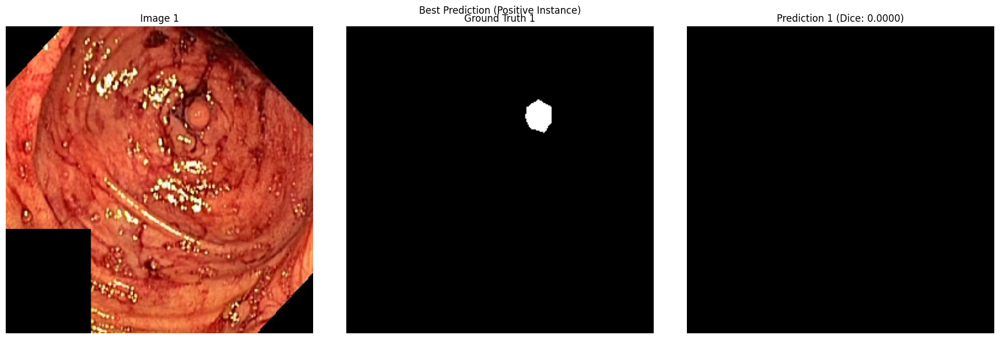

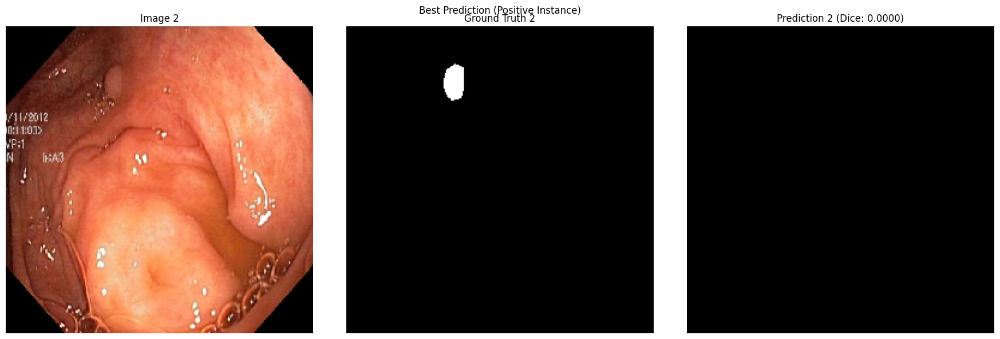

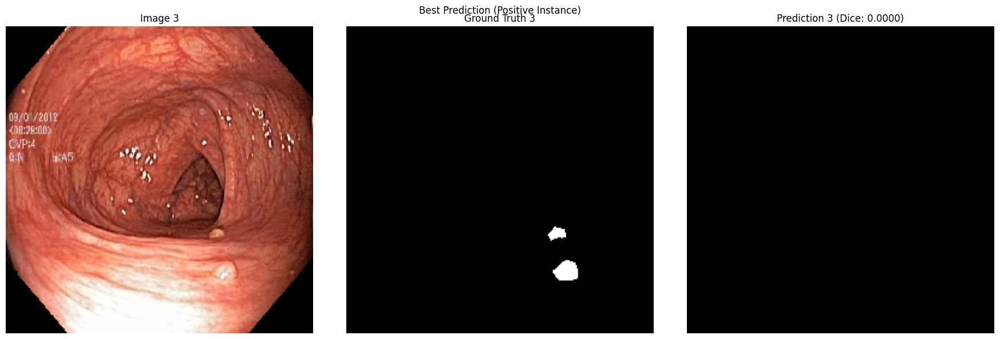

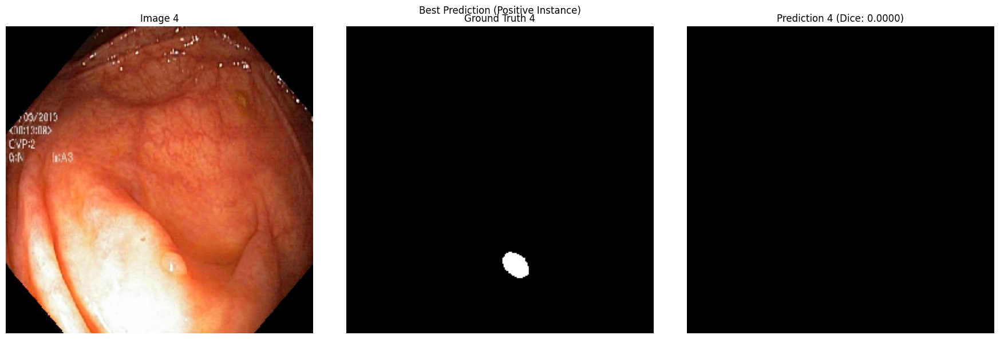

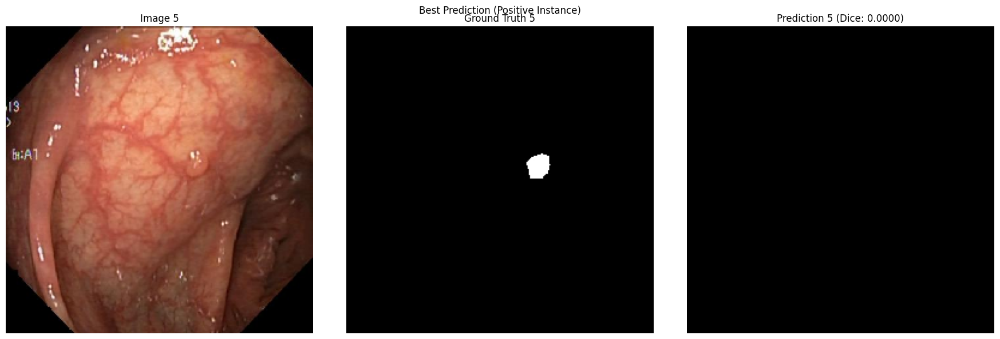

In [85]:
print("\nTop 5 Best Predictions (Positive instances only):")
if len(positive_results_bench) >= 5:
    for idx, result in enumerate(positive_results_bench[-5:]):
        display_image_gt_pred(result['image'], result['ground_truth'], result['prediction'],
                              result['dice_score'], idx, title='Best Prediction (Positive Instance)')
else:
    print(f"Only {len(positive_results_bench)} positive instances available:")
    for idx, result in enumerate(positive_results_bench):
        display_image_gt_pred(result['image'], result['ground_truth'], result['prediction'],
                              result['dice_score'], idx, title='Best Prediction (Positive Instance)')


In [89]:
!zip outputs /kaggle/working/outputs/*

  adding: kaggle/working/outputs/augmented_image_1.pdf (deflated 46%)
  adding: kaggle/working/outputs/augmented_image_2.pdf (deflated 55%)
  adding: kaggle/working/outputs/augmented_image_3.pdf (deflated 60%)
  adding: kaggle/working/outputs/augmented_image_4.pdf (deflated 49%)
  adding: kaggle/working/outputs/augmented_image_5.pdf (deflated 53%)
  adding: kaggle/working/outputs/augmented_image_6.pdf (deflated 47%)
  adding: kaggle/working/outputs/augmented_image_7.pdf (deflated 50%)
  adding: kaggle/working/outputs/augmented_image_8.pdf (deflated 49%)
  adding: kaggle/working/outputs/best_model_epoch_12.pth (deflated 7%)
  adding: kaggle/working/outputs/best_model_epoch_14.pth (deflated 7%)
  adding: kaggle/working/outputs/best_model_epoch_17.pth (deflated 7%)
  adding: kaggle/working/outputs/best_model_epoch_18.pth (deflated 7%)
  adding: kaggle/working/outputs/best_model_epoch_1.pth (deflated 8%)
  adding: kaggle/working/outputs/best_model_epoch_20.pth (deflated 7%)
  adding: kaggl